<a href="https://colab.research.google.com/github/embark-cybertraining/embark-scratch-notebooks/blob/main/sessions_1_and_2/ooi_cruises_bcodmo_argo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2026-10-14 Updated Session 2 only
# Prototype combined notebook for EMBARK CyberTraining Sessions 1 and 2

## Use Case Goal:

An oceanographer would like to visualize salinity by depth at a deep ocean study site with multiple cruises over several years.
As a CI user, s/he will (find), access, and use data from external sources to plot salinity by depth over a several-year time period for a location in which some of the profiles were collected by ship-based CTD rosette casts and others were sensed by Argo floats.

* Data repositories: BCO-DMO, NCEI
* Ocean observing systems: Argo, U.S. NSF OOI

* Tools include: ERDDAP, Python software libraries (e.g., pandas, erddapy, argopy)

This notebook may be run locally, or within cloud-based computing infrastructure (e.g., Google Colab, OOI JupyterHub).

## Session 1
Visualize 10 years of discrete water sampling data from annual research cruises and overlay with post-calibrated, ship-cast CTD profiles
## Session 2
Fill in the time gaps between research cruises with CTD profile data from autonomous floats

## Credits for this notebook
* The first portion builds on a notebook from the OOI CGSN Data Team https://github.com/WHOIGit/ooi-on-bco-dmo/blob/main/notebooks/0-OOI-Irminger-discrete-sample-article-figures.ipynb
* Overall the notebook was developed by the EMBARK CyberTraining project team, including Amber York, Sage Lichtenwalner, and Stace Beaulieu.
* Where indicated, some code was generated or improved by AI coding assistance, including ChatGPT.

# SESSION 2
Fill in the time gaps between research cruises with CTD profile data from autonomous floats

## Setup


In [1]:
#install libraries required for Session 2
%pip install -q argopy cmocean

Note: you may need to restart the kernel to use updated packages.


In [2]:
#import libraries required for Session 2
from argopy import DataFetcher # https://argopy.readthedocs.io/en/latest/generated/argopy.fetchers.ArgoDataFetcher.html
import pandas as pd
import matplotlib.pyplot as plt
import cmocean.cm as cmo

# Part A

## Step 1 - Discover - Argo float profiles

The CI user already will have found argopy, a tool to find, access, and use Argo float data.

Argopy documentation indicates the default data source is:

https://erddap.ifremer.fr/erddap/info/ArgoFloats/index.html

### Inspect data/metadata for context

## Step 2 - Access data


In [3]:
# Setup argopy DataFetcher to query Argo data ('phy' default or 'bgc' dataset) for a given space/time region
#standard mode
#f = DataFetcher().region([-40, -39, 59.5, 60.5, 0, 1000, '2014-01-01', '2024-12-31']) # to 1000 m with default source erddap and default standard mode
#f = DataFetcher(src='gdac').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with source GDAC and default standard mode

#research mode
f = DataFetcher(mode='research').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with default source erddap and research mode
#f = DataFetcher(mode='research', src='gdac').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with source GDAC and research mode

(<Figure size 900x540 with 1 Axes>,
 <Axes: xlabel='longitude', ylabel='latitude'>)

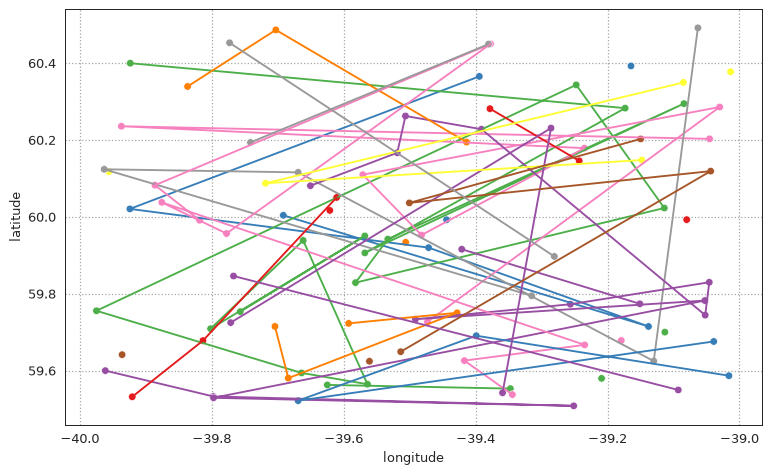

In [4]:
# The DataFetcher method has a quick method to plot profile trajectories
f.plot('trajectory')

In [5]:
%%time
# Load the data into a pandas DataFrame.  This can take a long time if you request a lot of data.
# How much time does this take? (4 minutes for GDAC 1 deg)
df_argo_profiles = f.to_dataframe().reset_index()

# "Internally, Argopy often works with xarray and the implementation of to_dataframe()
# converts the loaded dataset to a DataFrame before returning it.
# So while you can use a DataFrame directly, under the hood xarray may still be involved."

#"For many Argo workflows (e.g., extracting temperature/salinity profiles and doing statistical analysis),
# a DataFrame is perfectly fine and often more convenient.
# For gridding, interpolation, or working with profile dimensions, xarray is usually the better choice."

# # Call head() to view top of data frame
# df_argo_profiles.head()
df_argo_profiles


CPU times: user 9.1 ms, sys: 124 μs, total: 9.23 ms
Wall time: 9.03 ms


,N_POINTS,CYCLE_NUMBER,DIRECTION,PLATFORM_NUMBER,PRES,PRES_ERROR,PSAL,PSAL_ERROR,TEMP,TEMP_ERROR,LATITUDE,LONGITUDE,TIME
0,0,40,A,6901489,3.100000,2.400,34.941002,0.010,4.944,0.002,60.19476,-39.413708,2014-01-17 14:33:00
1,1,40,A,6901489,3.200000,2.400,34.941002,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
2,2,40,A,6901489,3.500000,2.400,34.942001,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
3,3,40,A,6901489,3.700000,2.400,34.941002,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
4,4,40,A,6901489,3.800000,2.400,34.939999,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
54133,54133,110,A,6903041,2792.500000,3.164,34.893211,0.006,1.479,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54134,54134,110,A,6903041,2793.699951,3.164,34.893211,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54135,54135,110,A,6903041,2794.399902,3.164,34.893200,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54136,54136,110,A,6903041,2795.600098,3.165,34.893200,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00


In [6]:
%%time
# We can also load just the index into a pandas DataFrame, which is much faster.
df_index = f.index
df_index.head()

CPU times: user 793 μs, sys: 83 μs, total: 876 μs
Wall time: 883 μs


,date,latitude,longitude,wmo,cyc
0,2014-07-11 12:51:04,60.017000,-39.621000,4901416,73
1,2017-06-18 03:52:00,60.004280,-39.691483,4901809,40
2,2017-07-18 03:51:00,59.715099,-39.137901,4901809,43
3,2017-07-28 03:45:00,59.920170,-39.471260,4901809,44
4,2017-08-07 03:49:00,60.020939,-39.924137,4901809,45


In [7]:
%%time
# We can touch on xarray in Session 2 as motivation for covering it in Session 4.
# Load the data into an xarray Dataset.  This can take a long time if you request a lot of data.
# How much time does this take?
ds_data = f.data # calls on DataFetcher.to_xarray() if not already in memory
ds_data

# compare timing to loading as data frame
# compare the cell output below to the output when displaying data frame above

CPU times: user 733 μs, sys: 0 ns, total: 733 μs
Wall time: 740 μs


<xarray.Dataset> Size: 4MB
Dimensions:          (N_POINTS: 54138)
Coordinates:
  * N_POINTS         (N_POINTS) int64 433kB 0 1 2 3 ... 54134 54135 54136 54137
    LATITUDE         (N_POINTS) float64 433kB 60.19 60.19 60.19 ... 59.9 59.9
    LONGITUDE        (N_POINTS) float64 433kB -39.41 -39.41 ... -39.28 -39.28
    TIME             (N_POINTS) datetime64[ns] 433kB 2014-01-17T14:33:00 ... ...
Data variables:
    CYCLE_NUMBER     (N_POINTS) int64 433kB 40 40 40 40 40 ... 110 110 110 110
    DIRECTION        (N_POINTS) <U1 217kB 'A' 'A' 'A' 'A' ... 'A' 'A' 'A' 'A'
    PLATFORM_NUMBER  (N_POINTS) int64 433kB 6901489 6901489 ... 6903041 6903041
    PRES             (N_POINTS) float32 217kB 3.1 3.2 ... 2.796e+03 2.796e+03
    PRES_ERROR       (N_POINTS) float32 217kB 2.4 2.4 2.4 ... 3.164 3.165 3.165
    PSAL             (N_POINTS) float32 217kB 34.94 34.94 34.94 ... 34.89 34.89
    PSAL_ERROR       (N_POINTS) float32 217kB 0.01 0.01 0.01 ... 0.006 0.006
    TEMP             (N_POINTS) float32 217kB 4.944 4.945 4.945 ... 1.478 1.477
    TEMP_ERROR       (N_POINTS) float32 217kB 0.002 0.002 0.002 ... 0.002 0.002
Attributes:
    DATA_ID:              ARGO
    DOI:                  http://doi.org/10.17882/42182
    Fetched_from:         erddap.ifremer.fr
    Fetched_by:           jovyan
    Fetched_date:         2026/10/20
    Fetched_constraints:  [x=-40.00/-39.00; y=59.50/60.50; z=0.0/5000.0; t=20...
    Fetched_uri:          https://erddap.ifremer.fr/erddap/tabledap/ArgoFloat...
    Processing_history:   [POSITION_QC,TIME_QC] filtered to retain points wit...

In [8]:
# if we start by loading with xarray, we can convert to data frame
# And can convert the 1D point data to a data frame
df_argo = ds_data.to_dataframe()
df_argo = df_argo.reset_index()
df_argo

# is df_argo equiv to df_argo_profiles ?

,N_POINTS,CYCLE_NUMBER,DIRECTION,PLATFORM_NUMBER,PRES,PRES_ERROR,PSAL,PSAL_ERROR,TEMP,TEMP_ERROR,LATITUDE,LONGITUDE,TIME
0,0,40,A,6901489,3.100000,2.400,34.941002,0.010,4.944,0.002,60.19476,-39.413708,2014-01-17 14:33:00
1,1,40,A,6901489,3.200000,2.400,34.941002,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
2,2,40,A,6901489,3.500000,2.400,34.942001,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
3,3,40,A,6901489,3.700000,2.400,34.941002,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
4,4,40,A,6901489,3.800000,2.400,34.939999,0.010,4.945,0.002,60.19476,-39.413708,2014-01-17 14:33:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
54133,54133,110,A,6903041,2792.500000,3.164,34.893211,0.006,1.479,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54134,54134,110,A,6903041,2793.699951,3.164,34.893211,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54135,54135,110,A,6903041,2794.399902,3.164,34.893200,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00
54136,54136,110,A,6903041,2795.600098,3.165,34.893200,0.006,1.478,0.002,59.89727,-39.280600,2024-06-17 15:39:00


In [9]:
# Save full Argo dataframe (just in case)
#df_argo.to_csv("argo_subset_points.csv", index=False)

In [10]:
# disaster recovery option
#df_argo = pd.read_csv("argo_subset_points.csv")
#df_argo

## Step 3 - Wrangle - Transform and QC (if needed)

## Step 4 - Reuse - Visualize Argo Data

In [11]:
# Assign colormaps from cmocean package
cmap_salt = cmo.haline
cmap_time = cmo.tempo_r

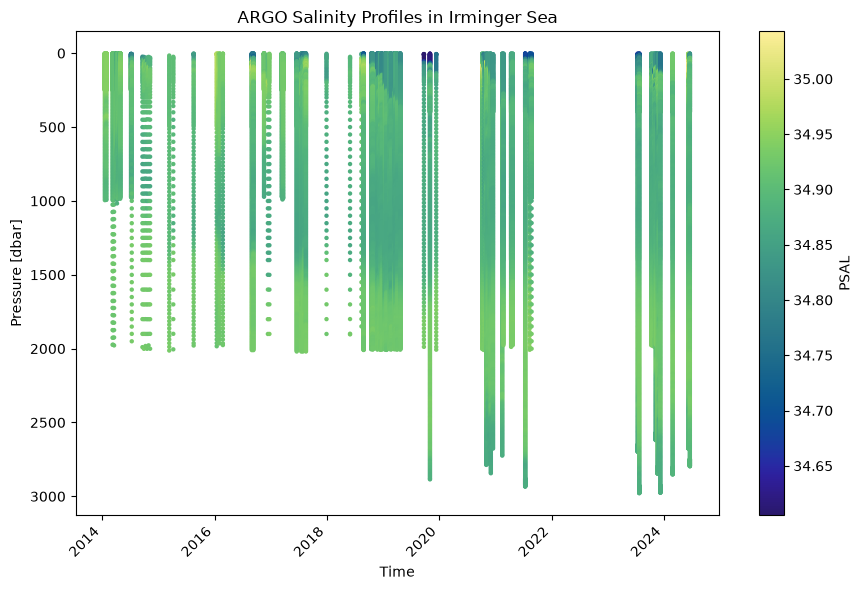

In [12]:
#using matplotlib

# this is using data frame
df_argo_profiles["TIME"] = pd.to_datetime(
    df_argo_profiles["TIME"], utc=True, errors="coerce"
)

# Drop rows missing the fields needed for plotting
c = df_argo_profiles.dropna(
    subset=["TIME", "PRES", "PSAL"]
).copy()

fig, ax = plt.subplots(figsize=(9, 6))

sc = ax.scatter(
    c["TIME"],
    c["PRES"],
    c=c["PSAL"],
    s=10,
    cmap=cmap_salt,
    #alpha=0.25,
    edgecolors="none"
)

ax.invert_yaxis()
ax.set_title("ARGO Salinity Profiles in Irminger Sea")
ax.set_xlabel("Time")
ax.set_ylabel("Pressure [dbar]")

# Rotate time labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("PSAL")

plt.tight_layout()
plt.show()

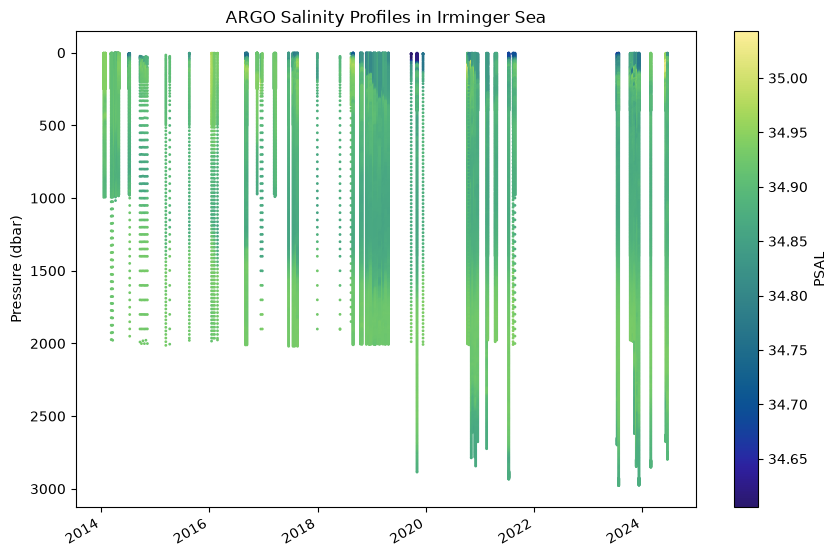

In [13]:
# note this is using the xarray data array
#import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))
#sc = ax.scatter(x=ds_data['TIME'], y=ds_data['PRES'], c=ds_data['TEMP'], s=1, cmap='plasma')
sc = ax.scatter(x=ds_data['TIME'], y=ds_data['PRES'], c=ds_data['PSAL'], s=1, cmap=cmap_salt)
#fig.colorbar(sc, ax=ax, label='Temperature (°C)')
fig.colorbar(sc, ax=ax, label='PSAL')

#ax.set_title('ARGO Temperature Profiles in Irminger Sea')
ax.set_title('ARGO Salinity Profiles in Irminger Sea')
ax.set_ylabel('Pressure (dbar)')
ax.invert_yaxis()
fig.autofmt_xdate()
plt.show()

# PART B - Visualize both datasets together

Let's look at both the data from sessions 1 (discrete salinity) and session 2 (argo profile salinity) together.

### Load Data from Session 1

In session 1 we loaded, subset, and saved this dataset to a csv:

Dataset: OOI Global Irminger Sea Array CTD and Discrete Water Sampling Data from Mooring Overturning Cruises in the Irminger Sea from 2014-2023 (OOI Cruise Data project)
* **Dataset Landing Page: https://www.bco-dmo.org/dataset/911407**

We subset that dataset with lat,lon bounds, and where the Discrete_Salinity_Flag indicated the data was good.  

In [14]:
# load data from session 1
import pandas as pd

df_ctd_discr_qc = pd.read_csv('session1_output/session1_df_ctd_discr_qc.csv')

# Ensure datetime
df_ctd_discr_qc["CTD_Bottle_Closure_Time"] = pd.to_datetime(
    df_ctd_discr_qc["CTD_Bottle_Closure_Time"], utc=True, errors="coerce"
)

#display the first few lines
df_ctd_discr_qc.head()

,Cruise,Target_Asset,Start_Latitude,Start_Longitude,Start_Time,Cast,Niskin_Bottle_Position,CTD_Bottle_Closure_Time,CTD_Pressure,CTD_Pressure_Flag,Discrete_Salinity,Discrete_Salinity_Flag
0,KN221-04,GI01SUMO,59.924168,-39.509335,2014-09-11T22:48:32.000Z,5,2,2014-09-11 23:17:06+00:00,1502.957,*0000000000000100,34.9323,*0000000000000100
1,KN221-04,GI01SUMO,59.924168,-39.509335,2014-09-11T22:48:32.000Z,5,4,2014-09-11 23:28:19+00:00,899.222,*0000000000000100,34.8664,*0000000000000100
2,KN221-04,GI01SUMO,59.924168,-39.509335,2014-09-11T22:48:32.000Z,5,6,2014-09-11 23:36:09+00:00,499.163,*0000000000000100,34.8934,*0000000000000100
3,KN221-04,GI01SUMO,59.924168,-39.509335,2014-09-11T22:48:32.000Z,5,10,2014-09-11 23:44:22+00:00,103.228,*0000000000000100,34.9467,*0000000000000100
4,KN221-04,GI01SUMO,59.924168,-39.509335,2014-09-11T22:48:32.000Z,5,18,2014-09-11 23:49:34+00:00,14.837,*0000000000000100,34.7811,*0000000000000100


### Inspect data/metadata together

For our usecase we want to know if we can use the salinity from both datsets together. Let's look at the documentation again and pull out what the salinity, pressure, lat, lon, and time reported in both datasets.  See if the type of measurement and units are compatible to use together.


In [15]:
# The OOI discrete dataset from BCO-DMO was loaded as a data frame that just has values (no metadata),
# so we have to look at the dataset landing page (or the lower part of the BCO-DMO ERDDAP dataset page).

# (Similarly for the Argo data frame you could look at the lower part of the Argo ERDDAP dataset page.)
# The Argo xarray dataset contains metadata
ds_data["PSAL"].attrs

{'long_name': 'PRACTICAL SALINITY',
 'standard_name': 'sea_water_salinity',
 'units': 'psu',
 'valid_min': 0.0,
 'valid_max': 43.0,
 'resolution': 0.001,
 'casted': 1}

 ### Visualize together

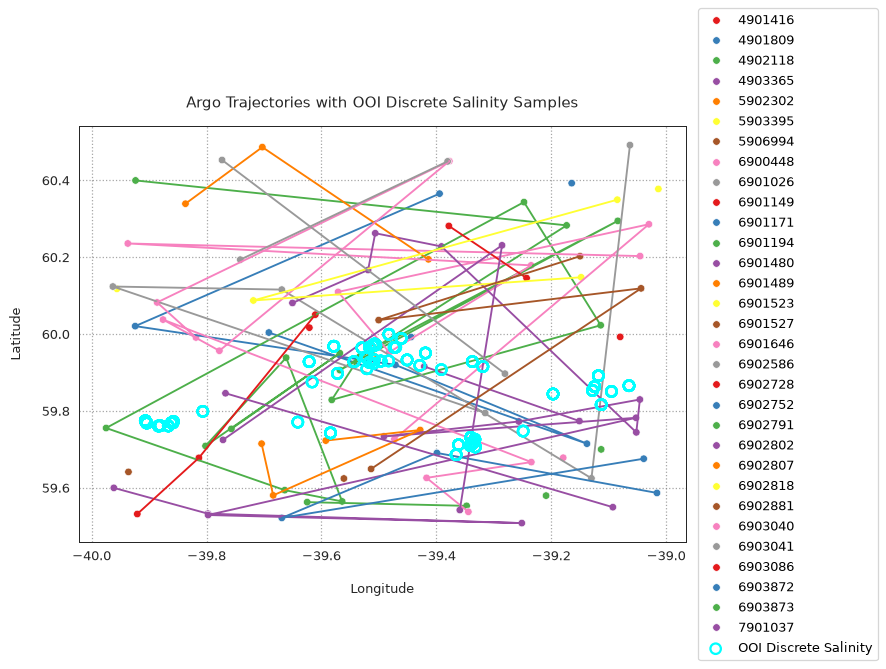

In [16]:
#import matplotlib.pyplot as plt

# Unpack figure and axis
fig, ax = f.plot("trajectory")

# # Subset to good salinity OOI samples
# ooi_pts = ooi_subset.loc[ooi_flag_sal].copy()

# # Overlay OOI discrete points
# ax.scatter(
#     ooi_pts["Start_Longitude"],
#     ooi_pts["Start_Latitude"],
#     s=70,
#     facecolors="none",
#     edgecolors="cyan",
#     linewidths=1.8,
#     zorder=5,
#     label="OOI discrete"
# )

# Overlay OOI discrete points
ax.scatter(
    df_ctd_discr_qc["Start_Longitude"],
    df_ctd_discr_qc["Start_Latitude"],
    s=70,
    facecolors="none",
    edgecolors="cyan",
    linewidths=1.8,
    zorder=5,
    label="OOI Discrete Salinity"
)

# Axis labels
ax.set_xlabel("Longitude", labelpad=15)
ax.set_ylabel("Latitude", labelpad=15)

# Title
ax.set_title("Argo Trajectories with OOI Discrete Salinity Samples", pad=15)

# Legend outside right
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)

# Make space for legend
plt.subplots_adjust(right=0.8)

plt.show()

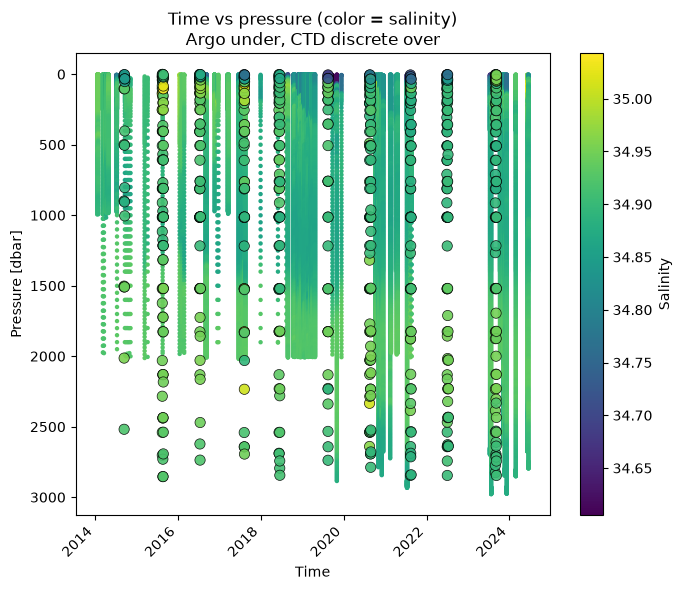

In [17]:
# Time vs. pressure, colored by salinity
# Argo profiles underneath, CTD discrete samples on top

#import matplotlib.pyplot as plt
#import pandas as pd

# Ensure datetime
df_argo_profiles["TIME"] = pd.to_datetime(
    df_argo_profiles["TIME"], utc=True, errors="coerce"
)

c = df_argo_profiles.dropna(
    subset=["TIME", "PRES", "PSAL"]
).copy()

fig, ax = plt.subplots(figsize=(7, 6))

# Argo underneath
sc = ax.scatter(
    c["TIME"],
    c["PRES"],
    c=c["PSAL"],
    s=10,
    #alpha=0.25,
    edgecolors="none"
)

# CTD discrete on top
ax.scatter(
    df_ctd_discr_qc["CTD_Bottle_Closure_Time"],
    df_ctd_discr_qc["CTD_Pressure"],
    c=df_ctd_discr_qc["Discrete_Salinity"],
    s=55,
    alpha=0.9,
    edgecolors="k",
    linewidths=0.5
)

ax.invert_yaxis()
ax.set_title("Time vs pressure (color = salinity)\nArgo under, CTD discrete over")
ax.set_xlabel("Time")
ax.set_ylabel("Pressure [dbar]")

# Rotate time labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Salinity")

plt.tight_layout()
plt.show()

## Same plot with plotly

In [18]:
import plotly.graph_objects as go
#import pandas as pd # imported at top of notebook
import numpy as np # needed for sal_min

# df_argo_profiles["TIME"] = pd.to_datetime(
#     df_argo_profiles["TIME"], utc=True, errors="coerce"
# )

# c = df_argo_profiles.dropna(
#     subset=["TIME", "PRES", "PSAL"]
# ).copy()

for col in ["PLATFORM_NUMBER", "LATITUDE", "LONGITUDE"]:
    if col in c.columns:
        c[col] = c[col].fillna("").astype(str)

# Shared salinity range across both datasets
sal_min = np.nanmin(np.r_[df_ctd_discr_qc["Discrete_Salinity"].values, c["PSAL"].values])
sal_max = np.nanmax(np.r_[df_ctd_discr_qc["Discrete_Salinity"].values, c["PSAL"].values])

fig = go.Figure()

# Argo underneath
argo_custom = c[["PLATFORM_NUMBER", "LATITUDE", "LONGITUDE"]].copy()
fig.add_trace(go.Scatter(
    x=c["TIME"],
    y=c["PRES"],
    mode="markers",
    marker=dict(
        size=4,
        color=c["PSAL"],
        colorscale="Viridis",
        cmin=sal_min,
        cmax=sal_max,
        opacity=0.3,
        showscale=True,
        colorbar=dict(title="Salinity")
    ),
    name="Argo profiles",
    customdata=argo_custom.to_numpy(),
    hovertemplate=(
        "Profile ID: %{customdata[0]}<br>"
        "Time: %{x|%Y-%m-%d %H:%M:%S}<br>"
        "Pressure: %{y:.1f} dbar<br>"
        "Salinity: %{marker.color:.4f}<br>"
        "Latitude: %{customdata[1]}<br>"
        "Longitude: %{customdata[2]}"
        "<extra></extra>"
    )
))

# CTD discrete on top
ctd_custom = df_ctd_discr_qc[["Cruise", "Cast", "Start_Latitude", "Start_Longitude"]].copy()
fig.add_trace(go.Scatter(
    x=df_ctd_discr_qc["CTD_Bottle_Closure_Time"],
    y=df_ctd_discr_qc["CTD_Pressure"],
    mode="markers",
    marker=dict(
        size=9,
        color=df_ctd_discr_qc["Discrete_Salinity"],
        colorscale="Viridis",
        cmin=sal_min,
        cmax=sal_max,
        line=dict(color="black", width=0.8),
        opacity=0.95,
        showscale=False
    ),
    name="CTD discrete",
    customdata=ctd_custom.to_numpy(),
    hovertemplate=(
        "Cruise: %{customdata[0]}<br>"
        "Cast: %{customdata[1]}<br>"
        "Time: %{x|%Y-%m-%d %H:%M:%S}<br>"
        "Pressure: %{y:.1f} dbar<br>"
        "Salinity: %{marker.color:.4f}<br>"
        "Latitude: %{customdata[2]}<br>"
        "Longitude: %{customdata[3]}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Time vs pressure (color = salinity)<br>Argo under, CTD discrete over",
    xaxis_title="Time",
    yaxis_title="Pressure (dbar)",
    legend_title="Source",
)

fig.update_yaxes(autorange="reversed")

fig.show()

# Wrapping up session 2

Let's get some information we can use in our documentation.

## When did you access your data?

In a notebook cell it's a good idea to print out the date (or datetime) when you ran your code. That way you have it for when you ever need that information in your documentation.

In [19]:
from datetime import datetime

print("Run datetime: " + datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

Run datetime: 2026-10-20 17:05:03


## What library versions did you use?

Below, we are printing the package versions ran with this notebook notebook in case we ever need to look back at this run and know when and what we were working with.  

In [20]:
from importlib.metadata import version

print("\nThis notebook was run with:")

print("argopy version: " + version("argopy"))
print("pandas version: " + version("pandas"))
print("matplotlib version: " + version("matplotlib"))
print("cmocean version: " + version("cmocean"))

# Above we just asked for main package versions, but even better is saving a
#     requirements.txt file which you can write with:
# !pip freeze > requirements.txt
#    will write you a file with ALL versions of everything in your environment



This notebook was run with:
argopy version: 1.5.0
pandas version: 3.0.6
matplotlib version: 3.11.2
cmocean version: 4.0.3


## Record your data citation

Record a data citation for any data sources you used.  This is a good practice for what to provide in reports, publications, or journal articles you might publish that used these data.

It's also valuable for the "future you" to have this record in case you want to come back later and work with these data again.

### Data from Session 1 - OOI data from BCO-DMO

We got this citation in session 1

> NSF Ocean Observatories Initiative (2025). OOI Global Irminger Sea Array CTD and Discrete Water Sampling Data from Mooring Overturning Cruises in the Irminger Sea from 2014-2023 (OOI Cruise Data project). Biological and Chemical Oceanography Data Management Office (BCO-DMO). (Version 1) Version Date 2023-10-24. doi:10.26008/1912/bco-dmo.911407.1

### Data from Session 2 - Argo data

From https://argo.ucsd.edu/data/acknowledging-argo/ asks you to do three things.  

1. Cite the paper

> Wong, A. P. S., et al. (2020), Argo Data 1999–2019: Two Million Temperature-Salinity Profiles and Subsurface Velocity Observations From a Global Array of Profiling Floats, Frontiers in Marine Science, 7(700), doi: https://doi.org/10.3389/fmars.2020.00700

2. Include this acknowledgement Sentence:

> These data were collected and made freely available by the International Argo Program and the national programs that contribute to it.  (https://argo.ucsd.edu,  https://www.ocean-ops.org).  The Argo Program is part of the Global Ocean Observing System.

3. Cite the data you used with the DOI

In [21]:
# Load the fetched data (f) (reuses data already in memory) and read argopy's metadata attributes
ds = f.load().data
doi = ds.attrs['DOI'].replace('http://', 'https://')
date = ds.attrs['Fetched_date']

# Print the general Argo data citation and access date
print(f"Argo (2000). Argo float data and metadata from Global Data Assembly Centre (Argo GDAC). SEANOE. {doi} (accessed {date})")

Argo (2000). Argo float data and metadata from Global Data Assembly Centre (Argo GDAC). SEANOE. https://doi.org/10.17882/42182 (accessed 2026/10/20)


# Additional Exercise: Methodology Summary - Argo Data Access

For our records and when sharing data or publishing data you can use this in your methodology description.

In [22]:
# Print the access description with the current date and installed argopy version
print(f"Argo profile data were retrieved on {datetime.now():%Y-%m-%d} using argopy {version('argopy')} "
      "through the Ifremer ERDDAP server (research mode, delayed-mode quality-controlled data). "
      "The query covered longitude -40 to -39, latitude 59.5 to 60.5, depth 0 to 5000 m, "
      "and 2014-01-01 to 2024-12-31.")


Argo profile data were retrieved on 2026-10-20 using argopy 1.5.0 through the Ifremer ERDDAP server (research mode, delayed-mode quality-controlled data). The query covered longitude -40 to -39, latitude 59.5 to 60.5, depth 0 to 5000 m, and 2014-01-01 to 2024-12-31.


In [23]:
#get info directly fetched data (f) (reuses data already in memory)

for k, v in f.load().data.attrs.items():
    print(f"{k}: {v}")


DATA_ID: ARGO
DOI: http://doi.org/10.17882/42182
Fetched_from: erddap.ifremer.fr
Fetched_by: jovyan
Fetched_date: 2026/10/20
Fetched_constraints: [x=-40.00/-39.00; y=59.50/60.50; z=0.0/5000.0; t=2014-01-01/2024-12-31]
Fetched_uri: https://erddap.ifremer.fr/erddap/tabledap/ArgoFloats.nc?config_mission_number,cycle_number,data_mode,direction,latitude,longitude,platform_number,position_qc,pres,pres_adjusted,pres_adjusted_error,pres_adjusted_qc,pres_qc,psal,psal_adjusted,psal_adjusted_error,psal_adjusted_qc,psal_qc,temp,temp_adjusted,temp_adjusted_error,temp_adjusted_qc,temp_qc,time,time_qc,vertical_sampling_scheme&longitude%3E=-40&longitude%3C=-39&latitude%3E=59.5&latitude%3C=60.5&pres_adjusted%3E=0&pres_adjusted%3C=5000&time%3E=1388534400.0&time%3C=1735603200.0&pres_adjusted!=NaN&temp_adjusted!=NaN&psal_adjusted!=NaN&latitude!=NaN&longitude!=NaN&distinct()&orderBy(%22time,pres_adjusted%22)
Processing_history: [POSITION_QC,TIME_QC] filtered to retain points with QC in [1]; [PRES,TEMP,PSAL

Note: The Fetched_uri above is the raw query argopy sent to ERDDAP. It contains characters that are not valid in a URL (double quotes, < and >), so clicking it as a link may return an error. Pasting it into a web browser's address bar usually works, because the browser encodes those characters automatically.

The web-safe version of the same query is below which you can click to open directly from this notebook. Opening it downloads the data as a NetCDF (.nc) file:

https://erddap.ifremer.fr/erddap/tabledap/ArgoFloats.nc?config_mission_number,cycle_number,data_mode,direction,latitude,longitude,platform_number,position_qc,pres,pres_adjusted,pres_adjusted_error,pres_adjusted_qc,pres_qc,psal,psal_adjusted,psal_adjusted_error,psal_adjusted_qc,psal_qc,temp,temp_adjusted,temp_adjusted_error,temp_adjusted_qc,temp_qc,time,time_qc,vertical_sampling_scheme&longitude%3E=-40&longitude%3C=-39&latitude%3E=59.5&latitude%3C=60.5&pres_adjusted%3E=0&pres_adjusted%3C=5000&time%3E=1388534400.0&time%3C=1735603200.0&pres_adjusted!=NaN&temp_adjusted!=NaN&psal_adjusted!=NaN&latitude!=NaN&longitude!=NaN&distinct()&orderBy(%22time,pres_adjusted%22)

# Additional Exercise: Check for Related Datasets
Let's end where we started.
We could extend the above to include data from the in situ wire-following profiler and profiling gliders in the U.S. NSF OOI Global Irminger Sea Array https://oceanobservatories.org/array/global-irminger-sea-array/.

For the composite dataset that inspired this use case, look for "Calibrated dissolved oxygen time series" in the "Related Datasets" section on the Dataset Landing Page: https://www.bco-dmo.org/dataset/911407
